# Vérification de l'environnement

Ce notebook vérifie que toutes les dépendances sont installées et fonctionnelles.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import sklearn
import torch
import torchvision

print(f"Python      : {sys.version}")
print(f"NumPy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"matplotlib  : {matplotlib.__version__}")
print(f"seaborn     : {sns.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"PyTorch     : {torch.__version__}")
print(f"torchvision : {torchvision.__version__}")
print(f"CUDA        : {torch.version.cuda}")

Python      : 3.13.18 (main, Oct 28 2026, 02:02:09) [GCC 14.2.0]
NumPy       : 2.5.4
pandas      : 3.1.0
matplotlib  : 3.11.2
seaborn     : 0.13.2
scikit-learn: 1.9.1
PyTorch     : 2.15.0+cpu
torchvision : 0.29.2+cpu
CUDA        : None


## Scikit-learn : LogisticRegression sur load_digits

In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

digits = load_digits()
X_train, X_test, y_train, y_test = train_test_split(
    digits.data, digits.target, test_size=0.2, random_state=42
)

clf = LogisticRegression(max_iter=5000, random_state=42)
clf.fit(X_train, y_train)
sk_acc = accuracy_score(y_test, clf.predict(X_test))
print(f"Scikit-learn accuracy : {sk_acc:.4f}")

Scikit-learn accuracy : 0.9750


## PyTorch : petit réseau sur load_digits avec DataLoader

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)

model = nn.Sequential(
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

losses = []
for epoch in range(50):
    epoch_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        loss = criterion(model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * X_batch.size(0)
    losses.append(epoch_loss / len(train_ds))

with torch.no_grad():
    preds = model(X_test_t).argmax(dim=1)
    pt_acc = (preds == y_test_t).float().mean().item()
print(f"PyTorch accuracy     : {pt_acc:.4f}")

PyTorch accuracy     : 0.9778


## Courbe de loss (pandas + seaborn)

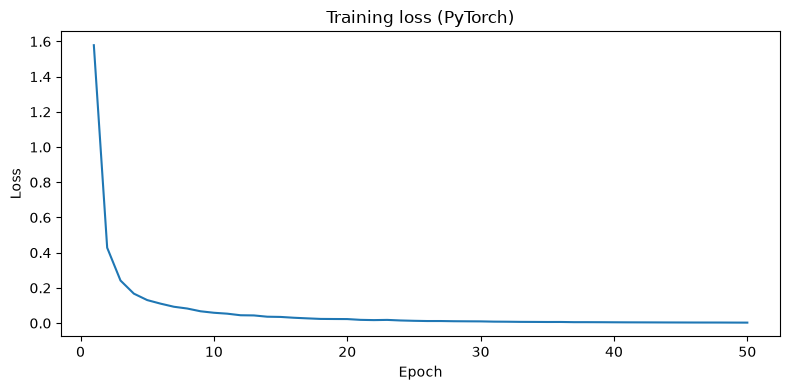


--- Résumé ---
Scikit-learn accuracy : 0.9750
PyTorch accuracy     : 0.9778


In [4]:
import matplotlib.pyplot as plt

df_loss = pd.DataFrame({"epoch": range(1, len(losses) + 1), "loss": losses})

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=df_loss, x="epoch", y="loss", ax=ax)
ax.set_title("Training loss (PyTorch)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
plt.tight_layout()
plt.show()

print(f"\n--- Résumé ---")
print(f"Scikit-learn accuracy : {sk_acc:.4f}")
print(f"PyTorch accuracy     : {pt_acc:.4f}")